# 04 · Gaussian chance constraints

> **In short:** a probabilistic constraint $P(\text{collision})\le\delta$ becomes a deterministic distance constraint with a margin proportional to the projected standard deviation. This notebook checks the formulas numerically with the package functions.
>
> **Runtime:** a few seconds · **Read alongside:** [Theory 13 · Chance constraints](../1.Docs/Theory/13_Chance_Constraints.md) · [Chance constraints (docs)](../2.Code/docs/concepts/chance-constraints.md)

**You will:**

- verify the Gaussian half-space lemma by sampling
- see that $\mathrm{erf}^{-1}(1-2\delta)\sqrt2$ (ODE track) equals $\Phi^{-1}(1-\epsilon)$ (native track)
- check that a zero chance residual really keeps the collision probability below δ
- see why the symmetric square root of Ω is required for rotated ellipsoids

## The lemma

For $x\sim\mathcal N(\hat x,\Sigma)$ and a half-space $a^Tx\le b$:

$$P(a^Tx\le b)=\Phi\!\left(\frac{b-a^T\hat x}{\sqrt{a^T\Sigma a}}\right)$$

so requiring the violation probability to be at most $\delta$ is equivalent to

$$a^T\hat x-b\ \ge\ \Phi^{-1}(1-\delta)\,\sqrt{a^T\Sigma a}=\mathrm{erf}^{-1}(1-2\delta)\sqrt{2\,a^T\Sigma a}.$$

In [1]:
from nbsetup import *

In [2]:
from scipy.stats import norm

from quadrotor_mpc.control.ccmpc.utils import erfinv

rng = np.random.default_rng(42)
mean = np.array([1.0, 2.0])
cov = np.diag([0.3, 0.5]) ** 2
a, b = np.array([1.0, -1.0]), -0.5
analytic = norm.cdf((b - a @ mean) / np.sqrt(a @ cov @ a))
sampled = np.mean(rng.multivariate_normal(mean, cov, 400_000) @ a <= b)
print(f"P(a'x <= b): analytic {analytic:.4f}, sampled {sampled:.4f}")
assert abs(analytic - sampled) < 0.003

for delta in (0.01, 0.03, 0.05, 0.10):
    print(f"delta={delta:.2f}: erfinv(1-2δ)·√2 = {erfinv(1 - 2 * delta) * np.sqrt(2):.4f}, "
          f"Φ⁻¹(1-δ) = {norm.ppf(1 - delta):.4f}")

P(a'x <= b): analytic 0.8044, sampled 0.8039
delta=0.01: erfinv(1-2δ)·√2 = 2.3263, Φ⁻¹(1-δ) = 2.3263
delta=0.03: erfinv(1-2δ)·√2 = 1.8808, Φ⁻¹(1-δ) = 1.8808
delta=0.05: erfinv(1-2δ)·√2 = 1.6449, Φ⁻¹(1-δ) = 1.6449
delta=0.10: erfinv(1-2δ)·√2 = 1.2816, Φ⁻¹(1-δ) = 1.2816


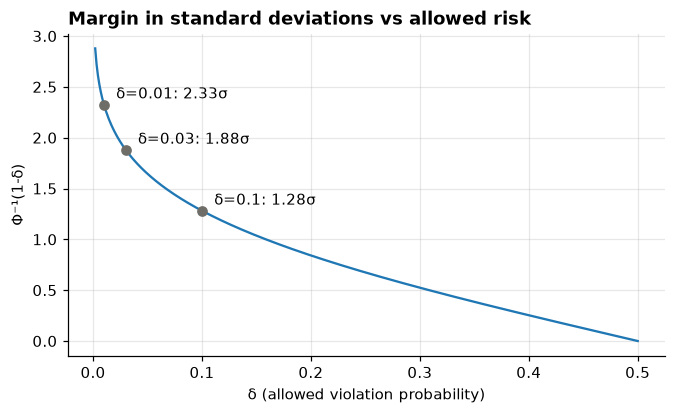

In [3]:
deltas = np.linspace(0.002, 0.5, 400)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(deltas, norm.ppf(1 - deltas))
for delta in (0.01, 0.03, 0.10):
    ax.plot(delta, norm.ppf(1 - delta), "o", color=NEUTRAL)
    ax.annotate(f"δ={delta}: {norm.ppf(1 - delta):.2f}σ", (delta, norm.ppf(1 - delta)),
                xytext=(8, 4), textcoords="offset points")
ax.set(title="Margin in standard deviations vs allowed risk", xlabel="δ (allowed violation probability)",
       ylabel="Φ⁻¹(1-δ)")
plt.show()

## Ellipsoidal obstacles (ODE track)

A box of size $(l,w,h)$ is enclosed by the ellipsoid with semi-axes $\tfrac{\sqrt3}{2}(l,w,h)$; the MAV
radius is added and the ellipsoid is rotated by its yaw, giving
$\Omega=R^T\,\mathrm{diag}\big((a_i+r)^{-2}\big)\,R$. With $S=\Omega^{1/2}$ the residual used by the
controller is

$$g=\|S(p-p_o)\|-1-\Phi^{-1}(1-\delta)\sqrt{n^TS(\Sigma+\Sigma_o)S^Tn},\qquad n=\frac{S(p-p_o)}{\|S(p-p_o)\|}.$$

$g\ge0$ means "safe at level δ" under the local Gaussian approximation. Below we place the MAV exactly
on $g=0$ and sample its position: the fraction of samples inside the ellipsoid must not exceed δ
(the linearization is conservative for a convex obstacle).

In [4]:
from scipy.optimize import brentq

from quadrotor_mpc.control.ccmpc.risk import chance_constraint_residual, symmetric_matrix_sqrt
from quadrotor_mpc.control.ccmpc.utils import Omega_matrix, box_to_ellipsoid_axes, yaw_to_rotation

obstacle = np.array([0.0, 0.0, 1.5])
axes_len = box_to_ellipsoid_axes(np.array([0.75, 0.55, 1.10]))
omega = Omega_matrix(axes_len, 0.3, yaw_to_rotation(0.45))
cov_mav = np.diag([0.10, 0.10, 0.05]) ** 2
cov_obs = np.diag([0.08, 0.08, 0.04]) ** 2
direction = np.array([1.0, 0.6, 0.0]) / np.linalg.norm([1.0, 0.6, 0.0])
samples = rng.multivariate_normal(np.zeros(3), cov_mav + cov_obs, 300_000)

print(" delta | empirical P(inside) | bound respected")
for delta in (0.01, 0.03, 0.10):
    distance = brentq(lambda d: chance_constraint_residual(obstacle + d * direction, obstacle, omega,
                                                            cov_mav, cov_obs, delta), 0.2, 5.0)
    relative = distance * direction + samples
    inside = np.einsum("ij,jk,ik->i", relative, omega, relative) <= 1.0
    print(f" {delta:5.2f} | {inside.mean():.4f}              | {inside.mean() <= delta}")
    assert inside.mean() <= delta

 delta | empirical P(inside) | bound respected
  0.01 | 0.0076              | True
  0.03 | 0.0239              | True
  0.10 | 0.0836              | True


## Why the symmetric square root?

The metric must satisfy $\|S(p-p_o)\|^2=(p-p_o)^T\Omega(p-p_o)$, which holds for the symmetric root
$S=\Omega^{1/2}$ (and for $L^T$ with a Cholesky factor $\Omega=LL^T$), but **not** for $L$ itself. For a
rotated ellipsoid, using $L$ silently changes the obstacle shape. The package uses
`symmetric_matrix_sqrt`, and a regression test locks this in.

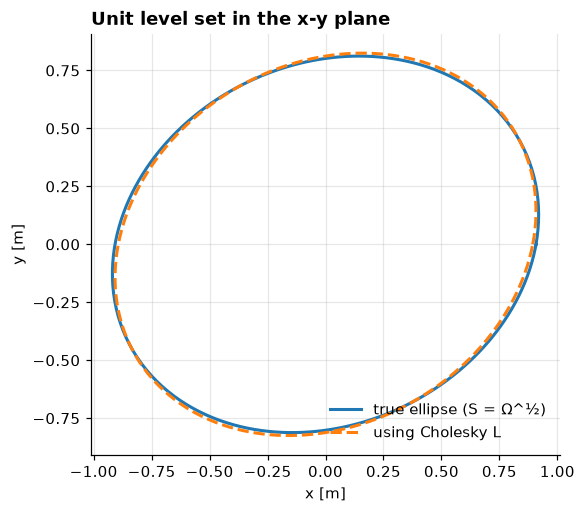

sqrt(d'Ωd) = 1.1327 | ||S d|| = 1.1327 | ||L d|| = 1.1144


In [5]:
S = symmetric_matrix_sqrt(omega)
L = np.linalg.cholesky(omega)
angles = np.linspace(0, 2 * np.pi, 361)
directions = np.stack([np.cos(angles), np.sin(angles), np.zeros_like(angles)], axis=1)

fig, ax = plt.subplots(figsize=(5.5, 5))
for name, root, style in (("true ellipse (S = Ω^½)", S, "-"), ("using Cholesky L", L, "--")):
    radius = 1.0 / np.linalg.norm(directions @ root.T, axis=1)  # points where ||root·d|| = 1
    ax.plot(radius * directions[:, 0], radius * directions[:, 1], style, lw=2, label=name)
ax.set(title="Unit level set in the x-y plane", xlabel="x [m]", ylabel="y [m]", aspect="equal")
ax.legend(loc="lower right")
plt.show()
d = directions[60]
print("sqrt(d'Ωd) =", np.sqrt(d @ omega @ d).round(4), "| ||S d|| =", np.linalg.norm(S @ d).round(4),
      "| ||L d|| =", np.linalg.norm(L @ d).round(4))
assert np.allclose(S @ S, omega)

## Takeaways

- Both tracks use the same idea; the ODE track writes the quantile as $\mathrm{erf}^{-1}(1-2\delta)\sqrt2$,
  the native track as $\Phi^{-1}(1-\epsilon)$. They are equal.
- The bound holds per constraint and per step. How several constraints share one budget is the
  [risk budget](../2.Code/docs/concepts/risk-budget.md), explored for the native track in notebook 07.

---

**Previous:** [03_ode_mpc_and_impc.ipynb](03_ode_mpc_and_impc.ipynb) · **Next:** [05_ode_controller_comparison.ipynb](05_ode_controller_comparison.ipynb)